# EMQA_L5_basis

**Basis Romania-Hungary and Romania-Germany**

Energy Markets Quantitative Analysis (EMQA), Lecture 5 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L5/EMQA_L5_basis/EMQA_L5_basis.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

The basis left by a Hungarian or German hedge, and how often the prices are equal.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5,
    'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
# fixed colour per entity (course palette)
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}


def legend_bottom(fig, handles=None, labels=None, ncol=4):
    """Legend centred under the axes, outside the plotting area."""
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                if l not in labels:
                    handles.append(h)
                    labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0),
               frameon=False, handlelength=2.0, columnspacing=1.2)


def legend_compact(fig, ncol):
    """Bottom legend with shorter handles and column gaps, for many short entries."""
    legend_bottom(fig, ncol=ncol)
    h, l = fig.legends[-1].legend_handles, [t.get_text() for t in fig.legends[-1].get_texts()]
    fig.legends[-1].remove()
    fig.legend(h, l, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0), frameon=False,
               handlelength=1.0, handletextpad=0.4, columnspacing=0.9)


def save_chart(fig, name):
    """Keep under the axes exactly the height of the bottom legend, then save the PNG."""
    fig.canvas.draw()
    bottom = max([lg.get_window_extent().height / fig.bbox.height + 0.035 for lg in fig.legends] or [0.0])
    fig.tight_layout(rect=(0, bottom, 1, 1))
    plt.savefig(name + '.png', dpi=150, bbox_inches='tight', transparent=True)
    plt.show()


def show(label, value, key=None, fmt='.2f'):
    """Print one number of the slide; [key] = its name in lectures/L5/L5_numbers.json."""
    s = value if isinstance(value, str) else format(value, fmt)
    print(f'{label:<58s} {s:>12s}' + (f'   [{key}]' if key else ''))

In [3]:
# daily day-ahead base prices (mean of all market time units of the CET/CEST day), EUR/MWh
PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet')
# cut-off = last complete month of the Romanian series
_last = PD['RO'].dropna().index.max()
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
d = lambda ts: pd.Timestamp(ts).strftime('%Y-%m-%d')
print('cut-off (last complete month):', d(END))

cut-off (last complete month): 2026-10-31


In [4]:
# monthly mean day-ahead prices, kept only for months with every day present
m_idx = pd.date_range('2015-01-01', END.replace(day=1), freq='MS')
PM = PD[['RO', 'HU', 'DE_LU']].resample('MS').mean().reindex(m_idx)
NDM = PD[['RO', 'HU', 'DE_LU']].resample('MS').count().reindex(m_idx)
PM = PM.where(NDM.eq(pd.Series(m_idx.days_in_month, index=m_idx), axis=0))

In [5]:
BAS = pd.DataFrame({'HU': PM['RO'] - PM['HU'], 'DE_LU': PM['RO'] - PM['DE_LU']})     # monthly basis
for z, nm in [('HU', 'Romania - Hungary'), ('DE_LU', 'Romania - Germany')]:
    b = BAS[z].dropna()
    show(f'{nm}: mean basis, EUR/MWh', b.mean(), f'basis.{z}.mean', '.2f')
    show(f'{nm}: std. dev. 2015-2020, EUR/MWh', b[:'2020-12-01'].std(), f'basis.{z}.sd_pre', '.2f')
    show(f'{nm}: std. dev. from 2021, EUR/MWh', b['2021-01-01':].std(), f'basis.{z}.sd_post', '.2f')
    show(f'{nm}: mean from 2023, EUR/MWh', b['2023-01-01':].mean(), f'basis.{z}.mean_post', '.2f')
    show(f'{nm}: largest monthly basis, EUR/MWh ({b.idxmax():%Y-%m})', b.max(), f'basis.{z}.max', '.2f')

# share of hours with the same price (|difference| < 0.01 EUR/MWh), weighted by duration (60/15-min units)
NP = pd.read_csv(DATA + 'power_da_prices_native_utc.csv', parse_dates=['timestamp_utc'],
                 usecols=['timestamp_utc', 'mtu_minutes', 'RO', 'HU', 'DE_LU']).set_index('timestamp_utc')
NP.index = NP.index.tz_convert('Europe/Brussels')
NP = NP.loc[:str(END.date())].copy()
NP['w'] = NP['mtu_minutes'] / 60
NP = NP[NP['RO'].notna() & NP['HU'].notna()]
wy = NP['w'].groupby(NP.index.year).sum()
conv = (NP['w'] * ((NP['RO'] - NP['HU']).abs() < 0.01)).groupby(NP.index.year).sum() / wy * 100
convd = (NP['w'] * ((NP['RO'] - NP['DE_LU']).abs() < 0.01)).groupby(NP.index.year).sum() / wy * 100
for y in conv.index:
    show(f'{y}: % of hours RO = HU', conv[y], f'basis.conv_hu.{y}', '.1f')
for y in convd.index:
    show(f'{y}: % of hours RO = DE', convd[y], f'basis.conv_de.{y}', '.1f')

Romania - Hungary: mean basis, EUR/MWh                            -2.08   [basis.HU.mean]
Romania - Hungary: std. dev. 2015-2020, EUR/MWh                    2.82   [basis.HU.sd_pre]
Romania - Hungary: std. dev. from 2021, EUR/MWh                    5.77   [basis.HU.sd_post]
Romania - Hungary: mean from 2023, EUR/MWh                        -0.99   [basis.HU.mean_post]
Romania - Hungary: largest monthly basis, EUR/MWh (2022-10)        12.12   [basis.HU.max]
Romania - Germany: mean basis, EUR/MWh                            13.95   [basis.DE_LU.mean]
Romania - Germany: std. dev. 2015-2020, EUR/MWh                    7.61   [basis.DE_LU.sd_pre]
Romania - Germany: std. dev. from 2021, EUR/MWh                   18.23   [basis.DE_LU.sd_post]
Romania - Germany: mean from 2023, EUR/MWh                        18.70   [basis.DE_LU.mean_post]
Romania - Germany: largest monthly basis, EUR/MWh (2024-07)        77.44   [basis.DE_LU.max]
2015: % of hours RO = HU                                         

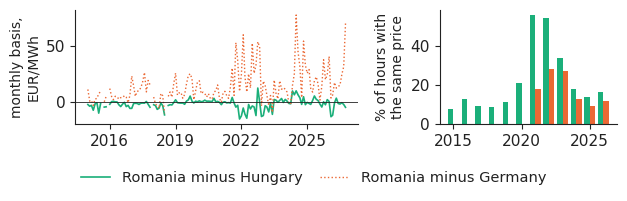

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(6.4, 2.05), gridspec_kw={'width_ratios': [1.6, 1]})
axs[0].plot(BAS.index, BAS['HU'], color=PAL['HU'], lw=1.2, label='Romania minus Hungary')
axs[0].plot(BAS.index, BAS['DE_LU'], color=PAL['DE_LU'], lw=1.0, ls=':', label='Romania minus Germany')
axs[0].axhline(0, color='#222222', lw=0.6)
axs[0].set_ylabel('monthly basis,\nEUR/MWh', fontsize=10)
axs[0].xaxis.set_major_locator(mdates.YearLocator(3))
axs[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
yy = [int(y) for y in conv.index]
axs[1].bar([y - 0.2 for y in yy], conv.values, width=0.4, color=PAL['HU'])
axs[1].bar([y + 0.2 for y in yy], convd.values, width=0.4, color=PAL['DE_LU'])
axs[1].set_ylabel('% of hours with\nthe same price', fontsize=10)
axs[1].set_xticks([2015, 2020, 2025])
legend_bottom(fig, ncol=2)
save_chart(fig, 'basis')